# 15 · SVM con kernel RBF sobre características espectrales (conjunto completo), versión con pesos de clase

Continuación del notebook 14. Se comprueba si el 91,2 % de la SVM lineal en prueba se debe a las características o a la frontera lineal.

**Cambio respecto a la versión anterior.** Todos los `LinearSVC` y `SVC` usan `class_weight="balanced"`, igual que la SVM lineal del notebook 14, para que la comparación entre núcleos sea justa. La búsqueda de γ y C se repite con pesos.

- **Experimento principal:** aproximación del kernel RBF con Nystroem + `LinearSVC`, entrenando con las 205.045 épocas de entrenamiento.
- **Comprobación secundaria (opcional):** `SVC` con kernel RBF exacto sobre un submuestreo estratificado.

Todos los modelos se evalúan sobre el mismo conjunto de prueba (12 sujetos, 44.733 épocas) que la SVM lineal, la CNN-1D y la EEGNet. Los hiperparámetros se eligen en validación y la prueba se usa una sola vez por modelo.

**Salidas que se guardan en `~/Desktop/TFM`:** `roc_svm_rbf.npz`, `resultados_svm_balanced.json`, `resultados_svm_rbf_balanced.csv`, `svm_rbf_hiperparametros_balanced.json` y las figuras en `images/`.

**Tiempo aproximado:** unos 10 minutos la búsqueda de γ y C, 1 minuto el modelo final. Las secciones 3 y 5 son opcionales.

In [1]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import LinearSVC, SVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

## Configuración
Revisa que `FEATURES_PATH` sea el mismo archivo que guardó el notebook 14.

In [2]:
DATA_DIR = os.path.expanduser("~/Desktop/TFM")
IMG_DIR = os.path.expanduser("~/Desktop/TFM/images")
os.makedirs(IMG_DIR, exist_ok=True)

FEATURES_PATH = os.path.join(DATA_DIR, "caracteristicas_svm_completo.npz")  # <- mismo nombre que en el notebook 14
RESULTS_CSV = os.path.join(DATA_DIR, "resultados_svm_rbf_balanced.csv")

RANDOM_STATE = 42
DPI = 150
CLASES = ["Vigilia", "Sueño"]       # se asume 0 = Vigilia, 1 = Sueño (se comprueba abajo)
N_COMPONENTS = 1000                  # nº de épocas de referencia de Nystroem (ver nota de memoria)
N_SUB = 30000                        # tamaño del submuestreo para el SVC exacto

assert os.path.exists(FEATURES_PATH), f"No encuentro {FEATURES_PATH}"


## Carga de características y estandarización
El `StandardScaler` se ajusta solo con train, igual que en el notebook 14.

In [3]:
d = np.load(FEATURES_PATH)
F_train, y_train = d["F_train"], d["y_train"]
F_val,   y_val   = d["F_val"],   d["y_val"]
F_test,  y_test  = d["F_test"],  d["y_test"]

print("Train:", F_train.shape, "| Val:", F_val.shape, "| Test:", F_test.shape)
for nombre, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    u, c = np.unique(y, return_counts=True)
    print(f"{nombre}: " + ", ".join(f"clase {k} = {v}" for k, v in zip(u, c)))

scaler = StandardScaler().fit(F_train)
X_train = scaler.transform(F_train)
X_val   = scaler.transform(F_val)
X_test  = scaler.transform(F_test)

Train: (205045, 30) | Val: (46265, 30) | Test: (44733, 30)
train: clase 0 = 115833, clase 1 = 89212
val: clase 0 = 25530, clase 1 = 20735
test: clase 0 = 25152, clase 1 = 19581


## Función de evaluación
El AUC se calcula con `decision_function`, que da la puntuación continua de la SVM.

In [4]:
def evaluar(modelo, X, y):
    t0 = time.time()
    puntuacion = modelo.decision_function(X)
    t_inf = time.time() - t0
    y_pred = (puntuacion > 0).astype(int)
    cm = confusion_matrix(y, y_pred)
    return {
        "acc": accuracy_score(y, y_pred),
        "f1_macro": f1_score(y, y_pred, average="macro"),
        "auc": roc_auc_score(y, puntuacion),
        "sens_vigilia": (y_pred[y == 0] == 0).mean(),
        "sens_sueno": (y_pred[y == 1] == 1).mean(),
        "err_vigilia_a_sueno": int(cm[0, 1]),
        "err_sueno_a_vigilia": int(cm[1, 0]),
        "t_inferencia_s": t_inf,
    }, y_pred, puntuacion


def ajustar(modelo, X, y):
    """Ajusta y devuelve el tiempo y los avisos de convergencia."""
    t0 = time.time()
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        modelo.fit(X, y)
    avisos = sorted({str(a.message)[:120] for a in w})
    return time.time() - t0, avisos

## 1. Referencia: SVM lineal (C = 0,01, con pesos de clase)
Se reentrena aquí para tener las dos SVM medidas en la misma ejecución y con el mismo hardware. Misma configuración que el notebook 14.

In [5]:
svm_lineal = LinearSVC(C=0.01, dual=False, max_iter=5000, random_state=RANDOM_STATE,
                       class_weight="balanced")
t_fit_lineal, avisos_lineal = ajustar(svm_lineal, X_train, y_train)

met_lineal_test, y_pred_lineal, punt_lineal = evaluar(svm_lineal, X_test, y_test)
met_lineal_test["t_ajuste_s"] = t_fit_lineal
print({k: round(float(v), 4) for k, v in met_lineal_test.items()})
print("Avisos de convergencia:", avisos_lineal if avisos_lineal else "ninguno")

{'acc': 0.9116, 'f1_macro': 0.9111, 'auc': 0.9751, 'sens_vigilia': 0.8781, 'sens_sueno': 0.9545, 'err_vigilia_a_sueno': 3065.0, 'err_sueno_a_vigilia': 890.0, 't_inferencia_s': 0.105, 't_ajuste_s': 1.63}
Avisos de convergencia: ninguno


## 2. Nystroem + LinearSVC (con pesos de clase): búsqueda de γ y C en validación

Nystroem elige `N_COMPONENTS` épocas de referencia y representa cada época por su similitud RBF con ellas. Un clasificador lineal sobre esa representación aproxima una SVM con kernel RBF.

Con características estandarizadas, el valor `gamma="scale"` de scikit-learn equivale a 1/30 ≈ 0,033, que se incluye en la búsqueda.

**Memoria:** la matriz transformada de train ocupa 205.045 × `N_COMPONENTS` × 8 bytes (≈ 1,6 GB con 1000 componentes). Por eso se usa 1000 y no más.

In [6]:
GAMMAS = [0.01, 0.033, 0.1]
CS = [0.1, 1, 10]

resultados_grid = []
for gamma in GAMMAS:
    for Cval in CS:
        modelo = make_pipeline(
            Nystroem(kernel="rbf", gamma=gamma, n_components=N_COMPONENTS, random_state=RANDOM_STATE),
            LinearSVC(C=Cval, dual=False, max_iter=5000, random_state=RANDOM_STATE,
                      class_weight="balanced"),
        )
        t_fit, avisos = ajustar(modelo, X_train, y_train)
        met, _, _ = evaluar(modelo, X_val, y_val)
        resultados_grid.append({"gamma": gamma, "C": Cval,
                                "acc_val": met["acc"], "f1_macro_val": met["f1_macro"],
                                "auc_val": met["auc"], "seg": t_fit})
        print(f"gamma={gamma:<6} C={Cval:<5} acc_val={met['acc']:.4f}  "
              f"f1_macro_val={met['f1_macro']:.4f}  ({t_fit:.1f}s)"
              + ("  [aviso de convergencia]" if avisos else ""))

df_grid = pd.DataFrame(resultados_grid)
df_grid

gamma=0.01   C=0.1   acc_val=0.9292  f1_macro_val=0.9282  (40.3s)
gamma=0.01   C=1     acc_val=0.9294  f1_macro_val=0.9284  (61.4s)
gamma=0.01   C=10    acc_val=0.9282  f1_macro_val=0.9272  (101.0s)
gamma=0.033  C=0.1   acc_val=0.9287  f1_macro_val=0.9276  (38.1s)
gamma=0.033  C=1     acc_val=0.9275  f1_macro_val=0.9264  (58.2s)
gamma=0.033  C=10    acc_val=0.9269  f1_macro_val=0.9258  (83.6s)
gamma=0.1    C=0.1   acc_val=0.9223  f1_macro_val=0.9209  (50.9s)
gamma=0.1    C=1     acc_val=0.9229  f1_macro_val=0.9216  (59.0s)
gamma=0.1    C=10    acc_val=0.9229  f1_macro_val=0.9216  (101.3s)


,gamma,C,acc_val,f1_macro_val,auc_val,seg
0,0.010,0.1,0.929212,0.928209,0.982945,40.279866
1,0.010,1.0,0.929428,0.928368,0.980059,61.439183
2,0.010,10.0,0.928239,0.927163,0.976402,101.015646
3,0.033,0.1,0.928650,0.927554,0.979857,38.079195
4,0.033,1.0,0.927505,0.926399,0.977110,58.167286
5,0.033,10.0,0.926899,0.925795,0.974319,83.572941
6,0.100,0.1,0.922252,0.920915,0.974306,50.853238
7,0.100,1.0,0.922857,0.921557,0.972721,58.981521
8,0.100,10.0,0.922922,0.921646,0.971665,101.308166


Se elige la combinación con mayor F1 macro en validación (desempate por accuracy).

Mejor configuración en validación: gamma = 0.01, C = 1.0


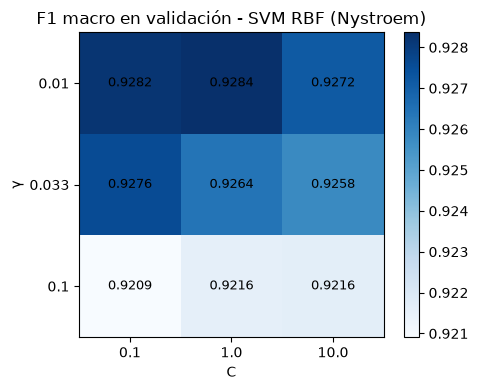

In [7]:
mejor = df_grid.sort_values(["f1_macro_val", "acc_val"], ascending=False).iloc[0]
GAMMA_BEST, C_BEST = float(mejor["gamma"]), float(mejor["C"])
print(f"Mejor configuración en validación: gamma = {GAMMA_BEST}, C = {C_BEST}")

# mapa de calor de la búsqueda
piv = df_grid.pivot(index="gamma", columns="C", values="f1_macro_val")
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(piv.values, cmap="Blues")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
ax.set_xlabel("C"); ax.set_ylabel("γ")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.values[i, j]:.4f}", ha="center", va="center", fontsize=9)
ax.set_title("F1 macro en validación - SVM RBF (Nystroem)")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "svm_rbf_grid_validacion.png"), dpi=DPI, bbox_inches="tight")
plt.show()

## 3. Estabilidad respecto al número de componentes (opcional)

Comprueba si 1000 componentes bastan. Si 500 y 1000 dan lo mismo en validación, la aproximación está estabilizada. La prueba con 2000 necesita unos 3,3 GB para la matriz transformada; si tu equipo va justo de RAM, quítala de la lista.

In [8]:
res_comp = []
for n in [500, 1000, 2000]:
    modelo = make_pipeline(
        Nystroem(kernel="rbf", gamma=GAMMA_BEST, n_components=n, random_state=RANDOM_STATE),
        LinearSVC(C=C_BEST, dual=False, max_iter=5000, random_state=RANDOM_STATE,
                  class_weight="balanced"),
    )
    t_fit, _ = ajustar(modelo, X_train, y_train)
    met, _, _ = evaluar(modelo, X_val, y_val)
    res_comp.append({"n_components": n, "acc_val": met["acc"],
                     "f1_macro_val": met["f1_macro"], "seg": t_fit})
    print(res_comp[-1])
pd.DataFrame(res_comp)

{'n_components': 500, 'acc_val': 0.9294499081379012, 'f1_macro_val': 0.9284201984310995, 'seg': 26.188640832901}
{'n_components': 1000, 'acc_val': 0.9294282935264239, 'f1_macro_val': 0.9283675225503201, 'seg': 55.13379192352295}
{'n_components': 2000, 'acc_val': 0.9298822003674484, 'f1_macro_val': 0.928830151380191, 'seg': 127.78821754455566}


,n_components,acc_val,f1_macro_val,seg
0,500,0.929450,0.928420,26.188641
1,1000,0.929428,0.928368,55.133792
2,2000,0.929882,0.928830,127.788218


## 4. Modelo final (Nystroem) y evaluación en test
Se entrena con la configuración elegida y se evalúa una única vez en test.

In [10]:
svm_rbf = make_pipeline(
    Nystroem(kernel="rbf", gamma=GAMMA_BEST, n_components=N_COMPONENTS, random_state=RANDOM_STATE),
    LinearSVC(C=C_BEST, dual=False, max_iter=5000, random_state=RANDOM_STATE,
              class_weight="balanced"),
)
t_fit_rbf, avisos_rbf = ajustar(svm_rbf, X_train, y_train)

met_rbf_test, y_pred_rbf, punt_rbf = evaluar(svm_rbf, X_test, y_test)
met_rbf_test["t_ajuste_s"] = t_fit_rbf

print(classification_report(y_test, y_pred_rbf, target_names=CLASES, digits=3))
print(f"ROC-AUC: {met_rbf_test['auc']:.4f}")
print(f"Tiempo de ajuste: {t_fit_rbf:.1f} s | inferencia sobre prueba: {met_rbf_test['t_inferencia_s']:.2f} s")
print("Avisos de convergencia:", avisos_rbf if avisos_rbf else "ninguno")
print(f"Configuración: gamma={GAMMA_BEST}, C={C_BEST}, n_components={N_COMPONENTS}")

              precision    recall  f1-score   support

     Vigilia      0.973     0.919     0.945     25152
       Sueño      0.903     0.967     0.934     19581

    accuracy                          0.940     44733
   macro avg      0.938     0.943     0.940     44733
weighted avg      0.942     0.940     0.940     44733

ROC-AUC: 0.9884
Tiempo de ajuste: 53.4 s | inferencia sobre prueba: 1.89 s
Avisos de convergencia: ninguno
Configuración: gamma=0.01, C=1.0, n_components=1000


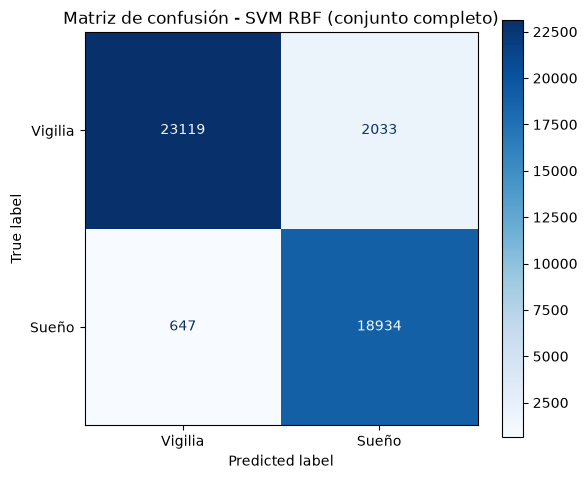

Guardado roc_svm_rbf.npz (AUC = 0.9884)


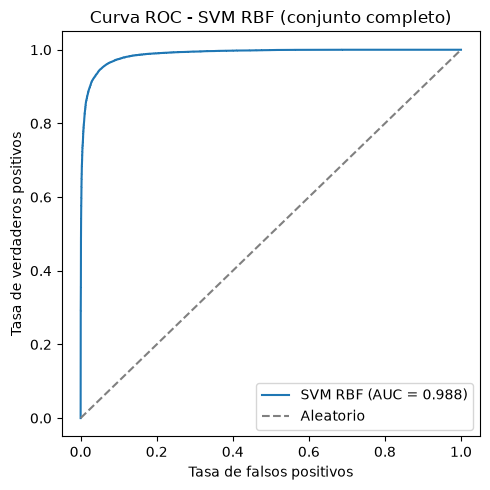

In [11]:
cm = confusion_matrix(y_test, y_pred_rbf)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Matriz de confusión - SVM RBF (conjunto completo)")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "svm_rbf_matriz_confusion.png"), dpi=DPI, bbox_inches="tight")
plt.show()

fpr, tpr, _ = roc_curve(y_test, punt_rbf)
np.savez(os.path.join(DATA_DIR, "roc_svm_rbf.npz"), fpr=fpr, tpr=tpr, auc=met_rbf_test["auc"])
print(f"Guardado roc_svm_rbf.npz (AUC = {met_rbf_test['auc']:.4f})")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"SVM RBF (AUC = {met_rbf_test['auc']:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Aleatorio")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curva ROC - SVM RBF (conjunto completo)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "svm_rbf_roc.png"), dpi=DPI, bbox_inches="tight")
plt.show()

## 5. Comprobación secundaria (opcional): SVC con RBF exacto sobre un submuestreo

Se toma un submuestreo estratificado de **train** (solo sujetos de train, sin fuga de información). Sobre ese mismo submuestreo se entrenan el `SVC` exacto y Nystroem, de modo que la única diferencia entre ambos es la aproximación del kernel. Si dan resultados parecidos, la aproximación de Nystroem es fiable.

C se vuelve a elegir en validación para el `SVC` exacto, porque su escala no tiene por qué coincidir con la del modelo aproximado. Cada ajuste puede tardar varios minutos.

In [12]:
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=N_SUB,
                                      stratify=y_train, random_state=RANDOM_STATE)
print("Submuestreo:", X_sub.shape, "| clases:", np.unique(y_sub, return_counts=True))

res_svc = []
for Cval in [0.1, 1, 10]:
    t0 = time.time()
    svc = SVC(kernel="rbf", gamma=GAMMA_BEST, C=Cval, cache_size=2000, class_weight="balanced")
    svc.fit(X_sub, y_sub)
    t_fit = time.time() - t0
    met, _, _ = evaluar(svc, X_val, y_val)
    res_svc.append({"C": Cval, "acc_val": met["acc"], "f1_macro_val": met["f1_macro"],
                    "n_vectores_soporte": int(svc.n_support_.sum()), "seg": t_fit})
    print(res_svc[-1])

df_svc = pd.DataFrame(res_svc)
C_SVC = float(df_svc.sort_values(["f1_macro_val", "acc_val"], ascending=False).iloc[0]["C"])
print("Mejor C para SVC exacto:", C_SVC)
df_svc

Submuestreo: (30000, 30) | clases: (array([0, 1]), array([16947, 13053]))
{'C': 0.1, 'acc_val': 0.9245866205554956, 'f1_macro_val': 0.9238455123200993, 'n_vectores_soporte': 6098, 'seg': 17.84110975265503}
{'C': 1, 'acc_val': 0.929557981195288, 'f1_macro_val': 0.9286560093933582, 'n_vectores_soporte': 4227, 'seg': 13.820579767227173}
{'C': 10, 'acc_val': 0.9290608451313087, 'f1_macro_val': 0.9279995431702727, 'n_vectores_soporte': 3400, 'seg': 10.277564525604248}
Mejor C para SVC exacto: 1.0


,C,acc_val,f1_macro_val,n_vectores_soporte,seg
0,0.1,0.924587,0.923846,6098,17.841110
1,1.0,0.929558,0.928656,4227,13.820580
2,10.0,0.929061,0.928000,3400,10.277565


In [13]:
# SVC exacto final sobre el submuestreo
t0 = time.time()
svc_final = SVC(kernel="rbf", gamma=GAMMA_BEST, C=C_SVC, cache_size=2000, class_weight="balanced").fit(X_sub, y_sub)
t_fit_svc = time.time() - t0
met_svc_test, _, _ = evaluar(svc_final, X_test, y_test)
met_svc_test["t_ajuste_s"] = t_fit_svc

# Nystroem con la configuración elegida, sobre el mismo submuestreo
t0 = time.time()
nys_sub = make_pipeline(
    Nystroem(kernel="rbf", gamma=GAMMA_BEST, n_components=N_COMPONENTS, random_state=RANDOM_STATE),
    LinearSVC(C=C_BEST, dual=False, max_iter=5000, random_state=RANDOM_STATE, class_weight="balanced"),
).fit(X_sub, y_sub)
t_fit_nys_sub = time.time() - t0
met_nys_sub_test, _, _ = evaluar(nys_sub, X_test, y_test)
met_nys_sub_test["t_ajuste_s"] = t_fit_nys_sub

print("SVC exacto (submuestreo):", {k: round(v, 4) for k, v in met_svc_test.items()})
print("Nystroem   (submuestreo):", {k: round(v, 4) for k, v in met_nys_sub_test.items()})

SVC exacto (submuestreo): {'acc': 0.9329, 'f1_macro': 0.9323, 'auc': 0.9839, 'sens_vigilia': np.float64(0.9076), 'sens_sueno': np.float64(0.9654), 'err_vigilia_a_sueno': 2325, 'err_sueno_a_vigilia': 678, 't_inferencia_s': 24.2361, 't_ajuste_s': 14.0223}
Nystroem   (submuestreo): {'acc': 0.9368, 'f1_macro': 0.9362, 'auc': 0.9863, 'sens_vigilia': np.float64(0.9144), 'sens_sueno': np.float64(0.9655), 'err_vigilia_a_sueno': 2152, 'err_sueno_a_vigilia': 676, 't_inferencia_s': 1.3365, 't_ajuste_s': 7.1826}


## 6. Resumen en test
Todas las filas usan el mismo conjunto de test.

In [14]:
filas = [
    ("SVM lineal (train completo)", met_lineal_test, len(y_train)),
    ("SVM RBF Nystroem (train completo)", met_rbf_test, len(y_train)),
    (f"SVM RBF Nystroem (submuestreo {N_SUB})", met_nys_sub_test, N_SUB),
    (f"SVM RBF exacto (submuestreo {N_SUB})", met_svc_test, N_SUB),
]
resumen = pd.DataFrame([{"Modelo": n, "Épocas train": m_train, **met} for n, met, m_train in filas])
resumen = resumen[["Modelo", "Épocas train", "acc", "f1_macro", "auc",
                   "sens_vigilia", "sens_sueno", "t_ajuste_s", "t_inferencia_s"]]
resumen.to_csv(RESULTS_CSV, index=False)

with open(os.path.join(DATA_DIR, "svm_rbf_hiperparametros_balanced.json"), "w") as f:
    json.dump({"gamma": GAMMA_BEST, "C_nystroem": C_BEST, "C_svc_exacto": C_SVC,
               "n_components": N_COMPONENTS, "n_sub": N_SUB}, f, indent=2)

resumen.round(4)

,Modelo,Épocas train,acc,f1_macro,auc,sens_vigilia,sens_sueno,t_ajuste_s,t_inferencia_s
0,SVM lineal (train completo),205045,0.9116,0.9111,0.9751,0.8781,0.9545,1.6300,0.1050
1,SVM RBF Nystroem (train completo),205045,0.9401,0.9396,0.9884,0.9192,0.9670,53.4271,1.8912
2,SVM RBF Nystroem (submuestreo 30000),30000,0.9368,0.9362,0.9863,0.9144,0.9655,7.1826,1.3365
3,SVM RBF exacto (submuestreo 30000),30000,0.9329,0.9323,0.9839,0.9076,0.9654,14.0223,24.2361


## 7. Cifras para la memoria
Esta celda imprime y guarda todo lo que necesita la tabla de resultados del conjunto completo. Pégame la salida de esta celda.

In [15]:
def a_json(m):
    return {k: (float(v) if not isinstance(v, int) else v) for k, v in m.items()}

salida = {
    "svm_lineal": a_json(met_lineal_test),
    "svm_rbf": a_json(met_rbf_test),
    "config_rbf": {"gamma": GAMMA_BEST, "C": C_BEST, "n_components": N_COMPONENTS,
                   "class_weight": "balanced"},
    "avisos_convergencia": {"lineal": avisos_lineal, "rbf": avisos_rbf},
    "errores_totales": {
        "lineal": met_lineal_test["err_vigilia_a_sueno"] + met_lineal_test["err_sueno_a_vigilia"],
        "rbf": met_rbf_test["err_vigilia_a_sueno"] + met_rbf_test["err_sueno_a_vigilia"],
    },
    "soporte_prueba": {"vigilia": int((y_test == 0).sum()), "sueno": int((y_test == 1).sum())},
}
with open(os.path.join(DATA_DIR, "resultados_svm_balanced.json"), "w") as f:
    json.dump(salida, f, indent=2, ensure_ascii=False)
print(json.dumps(salida, indent=2, ensure_ascii=False))

print()
print(classification_report(y_test, y_pred_lineal, target_names=CLASES, digits=3))

{
  "svm_lineal": {
    "acc": 0.9115865244897503,
    "f1_macro": 0.911074007775789,
    "auc": 0.9750998470436562,
    "sens_vigilia": 0.8781409033078881,
    "sens_sueno": 0.9545477759052142,
    "err_vigilia_a_sueno": 3065,
    "err_sueno_a_vigilia": 890,
    "t_inferencia_s": 0.1049802303314209,
    "t_ajuste_s": 1.6299693584442139
  },
  "svm_rbf": {
    "acc": 0.9400889723470368,
    "f1_macro": 0.9395599676072783,
    "auc": 0.9884172674041526,
    "sens_vigilia": 0.9191714376590331,
    "sens_sueno": 0.9669577651805321,
    "err_vigilia_a_sueno": 2033,
    "err_sueno_a_vigilia": 647,
    "t_inferencia_s": 1.8912405967712402,
    "t_ajuste_s": 53.4271023273468
  },
  "config_rbf": {
    "gamma": 0.01,
    "C": 1.0,
    "n_components": 1000,
    "class_weight": "balanced"
  },
  "avisos_convergencia": {
    "lineal": [],
    "rbf": []
  },
  "errores_totales": {
    "lineal": 3955,
    "rbf": 2680
  },
  "soporte_prueba": {
    "vigilia": 25152,
    "sueno": 19581
  }
}

       